In [3]:
# 引入Numpy和 Matplotlib库
import numpy as np
from matplotlib import pyplot as plt

"""
ax + by = c
"""


def draw_line(a, b, c, start=-10, stop=10, step=0.01):
    """根据线性方程参数绘制一条直线"""
    # 如果b为0，则画一条垂线
    if np.isclose(b, 0):
        plt.vlines(start, stop, c / a)
    else:  # 否则画 y = (c - a*x) / b
        xs = np.arange(start, stop, step)
        plt.plot(xs, (c - a * xs) / b)


def draw_lines_v1(coeffs, start=-10, stop=10, step=0.01):
    """
    根据线性方程参数绘制多条直线

    参数:
    coeffs: 二维数组或列表，形状为 (N, 3)，每一行代表 [a, b, c]
            对应方程 ax + by = c
    start, stop, step: x轴的绘图范围
    """
    coeffs = np.asarray(coeffs)

    # 确保是二维数组
    if coeffs.ndim == 1:
        coeffs = coeffs.reshape(1, -1)

    for a, b, c in coeffs:
        draw_line(a, b, c, start, stop, step)

    draw_coordinate_axis()


def draw_lines_v2(augmented, start=-4, stop=5, step=0.01):
    """Draw lines represented by augmented matrix on 2-d plane."""
    am = np.asarray(augmented)
    # print(am[:, [-1]])
    # print(am[:, [1]])
    # print(am[:, [0]])
    # 去掉第二列有0的行，避免除以0的情况
    am = am[~np.isclose(am[:, 1], 0)]

    # 生成x值的范围, -1 表示自动计算列数
    xs = np.arange(start, stop, step).reshape([1, -1])
    # print(xs.shape)

    ys = (am[:, [-1]] - am[:, [0]] * xs) / am[:, [1]]
    print(
        f"打印第一个点的坐标: {am[0][0]}, {am[0][1]}, {am[0][-1]}, {xs[0, :1]}, {ys[0, :1]}"
    )

    for y in ys:
        plt.plot(xs[0], y)

    draw_coordinate_axis()
    plt.show()


# 绘制坐标轴
def draw_coordinate_axis():
    # 添加 x 轴和 y 轴
    plt.axhline(0, color="black", linewidth=0.5)  # 绘制 x 轴 (y=0)
    plt.axvline(0, color="black", linewidth=0.5)  # 绘制 y 轴 (x=0)

    # 可选：添加网格
    plt.grid(True, linestyle="--", alpha=0.6)

    # 可选：设置标签和标题
    plt.xlabel("X axis")
    plt.ylabel("Y axis")
    # plt.title(f"Line: {a}x + {b}y = {c}")

打印第一个点的坐标: 1, -2, -1, [-4.], [-1.5]


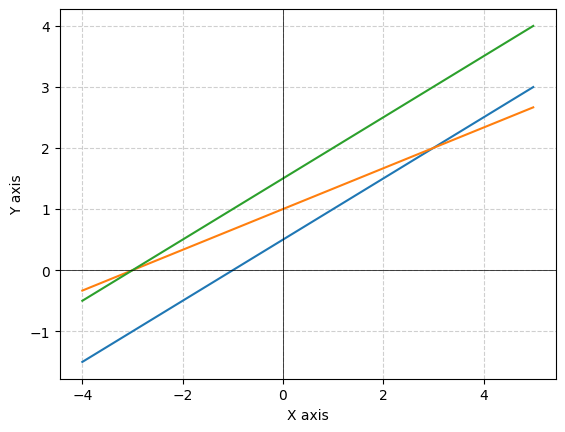

In [ ]:
# 代性代数及应用第三页

# draw_line(1, -2, -1)
# draw_line(-1, 3, 3)
# 两条直线的交点于一点。是 (1, 0)
# draw_line(1, -2, -1)
# draw_line(-1, 2, 3)
# 两条直线平行，没有交点

# fmt: off
# 增广矩阵，每行代表一个线性方程的系数和常数项 [a, b, c]， ax + by = c
equations = [[1, -2, -1],
             [-1, 3, 3], 
             [-1, 2, 3]
            ]
# fmt: on

# draw_lines_v1(equations)
draw_lines_v2(equations)